# Spatiotemporal feature-engineering shotgun — XGBoost

This notebook screens **all registered feature families** against your existing selected-binary XGBoost baseline. The baseline already contains historical comparable-sale features. Every feature variant is fitted on the same training sample and predicted on the same unseen held-out homes.

**Default experiment:** all `SCREEN_FEATURE_VARIANTS` (including the six new advanced families), 10,000 training sales, up to 1,000 August 2025 validation sales, and 220 XGBoost trees. Residual corrections are **disabled by default**, since we already evaluated those separately. Switch `RUN_RESIDUALS=True` in the settings cell only if you want to rerun the older residual family experiments.

Results are exploratory: these sampled, reduced-tree scores should **not** match the full-history 700-tree XGBoost (7.82% MdAPE). The validation month must be before December 2025; reserve later months for confirmation, since December 2025–May 2026 has already been used repeatedly.

**Files:** `summary.csv`, `predictions.csv`, `failures.json` in the unique `OUTPUT_DIR` below. The experiment does not modify saved baseline models or the production prediction pipeline.


In [1]:
import pandas as pd
from IPython.display import display
from spacetime_fast import run_shotgun, SCREEN_FEATURE_VARIANTS
from models.spacetime_screen_residuals import RESIDUAL_VARIANTS

VALIDATION_MONTH = "2025-08"
TRAIN_START = "2022-01-01"
TRAIN_CAP = 10000             # sample of historical completed sales
VALIDATION_CAP = 1000         # holdout sample, excluded from all training
SCREEN_TREES = 220           # small screen; full model uses 700
SEED = 42
OUTPUT_DIR = "outputs/spacetime_features_all"

RUN_RESIDUALS = False        # residual corrections tested separately
CALIBRATION_CAP = 650        # used only when RUN_RESIDUALS is True
CALIBRATION_FOLDS = 2
RESIDUAL_STRENGTH = 0.5

FEATURES = list(SCREEN_FEATURE_VARIANTS)
RESIDUALS = list(RESIDUAL_VARIANTS) if RUN_RESIDUALS else []

print(f"Feature candidates ({len(FEATURES)}):", FEATURES)
print("Residual candidates:", RESIDUALS)
print("Output:", OUTPUT_DIR)


Feature candidates (16): ['baseline', 'market', 'multiscale', 'time_adjusted_comp', 'spacetime_rbf', 'spacetime_splines', 'combined', 'adaptive_comps', 'hedonic_index', 'geo_context', 'property_spacetime', 'kalman_market', 'advanced_combined', 'comp_age_first', 'comp_type_quota', 'comp_both']
Residual candidates: []
Output: outputs/spacetime_features_all


In [4]:
scores, predictions, failures = run_shotgun(
    validation_month=VALIDATION_MONTH,
    train_start=TRAIN_START,
    train_cap=TRAIN_CAP,
    validation_cap=VALIDATION_CAP,
    calibration_cap=CALIBRATION_CAP,
    calibration_folds=CALIBRATION_FOLDS,
    screen_trees=SCREEN_TREES,
    seed=SEED,
    features=FEATURES,
    residuals=RESIDUALS,
    residual_strength=RESIDUAL_STRENGTH,
    output_dir=OUTPUT_DIR,
)
display(scores)
if failures:
    print(f"{len(failures)} failed candidates; see {OUTPUT_DIR}/failures.json")
    display(pd.DataFrame(failures)[["arm", "variant", "error"]])
else:
    print("All requested candidates finished successfully.")


Shotgun: 10,000 historical sales; 1,000 unseen 2025-08 homes; 220 trees per XGBoost


KeyboardInterrupt: 

In [ ]:
# Compare feature candidates to the same reduced-sample XGBoost baseline.
display(scores.sort_values(["arm", "mdape"]))
display(scores.groupby("arm")[["mdape", "mape", "delta_mdape_pp", "delta_mape_pp"]]
        .agg(["min", "median"]).round(3))

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, max(5, 0.4 * len(scores) + 1)))
p = scores.sort_values("delta_mdape_pp")
ax.barh(p["arm"] + " / " + p["variant"], p["delta_mdape_pp"])
ax.axvline(0, linewidth=1, color="gray")
ax.set_xlabel("MdAPE change from baseline (percentage points; lower is better)")
ax.set_title("Spatiotemporal feature shotgun")
fig.tight_layout()
plt.show()


In [ ]:
# Inspect whether variants help particular property types.
import data
sales = data.load("listings")
sold_month = pd.to_datetime(sales["date_sold"]).dt.to_period("M")
names = sales.loc[sold_month == pd.Period(VALIDATION_MONTH),
                  ["ml_num", "house_type_name"]]
annotated = predictions.merge(names, on="ml_num", how="left", validate="many_to_one")
subgroups = (annotated.groupby(["arm", "variant", "house_type_name"])
             .agg(n=("ml_num", "size"), mdape=("abs_pct_error", "median"))
             .query("n >= 10")
             .sort_values(["house_type_name", "mdape"]))
display(subgroups.head(50))
print(f"Full result CSV: {OUTPUT_DIR}/predictions.csv")


## Next: refine the winners

Review `summary.csv` and `failures.json`. Keep 3–5 candidates with the strongest MdAPE/MAPE and reasonable runtime. Confirm them across multiple **earlier** validation months in `spacetime_three_month.ipynb` using 40,000 training examples and 500 trees; for that notebook set `FEATURE_VARIANTS` to the shortlist and `RESIDUAL_VARIANTS=[]`.

A small change on one month can be noise or selection bias. Only promote persistent improvements to full-history 700-tree validation. The baseline and shortlisted variants must use identical chronological splits and target definitions.

If your local repo is behind, update it and open this notebook in Jupyter:

```powershell
git switch main
git pull origin main
uv sync
uv run jupyter lab
```

For a quicker initial screen, change `TRAIN_CAP=5000`, `VALIDATION_CAP=400`, and `SCREEN_TREES=100`; for a stronger screen increase those settings, but retain the same holdout across variants.


---

## Structural spatiotemporal shotgun — Matérn GP and local kernels

**This is a separate experiment from the feature-engineering shotgun above.** Run the new cells below; the earlier feature-screening cells do **not** need to be rerun.

We test actual model structures, not just new features:

| Model | Role |
| --- | --- |
| `baseline` | Matched tuned **XGBoost + splines + geo** |
| `xgb_tensor_gam` | Matched XGBoost + splines + geo **+ Tensor GAM** (strong incumbent) |
| `xgb_st_kernel` / `xgb_st_kernel_type` | Out-of-time local space-time kernel corrections |
| `xgb_spatial_matern` | Exact spatial Matérn GP correction |
| `xgb_st_matern` | Exact three-dimensional space-time Matérn GP correction |
| `gpboost_vecchia` | **Archived, excluded from active screens:** independent boosted-trees + spatiotemporal GP |

All methods use the **same sampled training period** and **identical held-out homes**, with strict chronological cutoffs. Corrections use *earlier out-of-time errors*, never their own training errors.

**Screening is not final validation.** Our full-history off-market best remains **7.4857% MdAPE**. The pilot trains fewer XGBoost trees and sales; compare *deltas against this pilot's matched incumbent*, **not** raw MdAPE against the full-history best. A one-month smoke test is for functional checks only. The three-month test helps select candidates for full-history confirmation.

Implementations: `models/spacetime_structural_features.py`, `models/spacetime_structural_residuals.py`, `models/spacetime_gpboost.py`. The root `spacetime_structural_shotgun.py` only coordinates evaluation, checkpointing and comparisons. **GPBoost is excluded from the active method set.** Its October 2025 diagnosis showed 48.7828% MdAPE both with and without the GP component (compared with 10.9349% for the matched XGBoost), so additional GPU/CPU budget is better spent on the Matérn residual models. The GPBoost code and diagnostics remain for reproducibility.


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from spacetime_structural_shotgun import run_structural_shotgun, METHODS
from models.spacetime_structural_features import SPLINE_GEO_SUFFIX

assert SPLINE_GEO_SUFFIX == "__st_spacetime_splines+geo_context"
assert "xgb_tensor_gam" in METHODS
# GPBoost is deliberately excluded: the fitted tree-only and combined
# predictions were equally poor (48.78% MdAPE in the matched smoke fold).
ACTIVE_STRUCTURAL_METHODS = tuple(
    variant for variant in METHODS if variant != "gpboost_vecchia"
)

# Independent output folders prevent the small smoke run from contaminating
# a larger three-month experiment. Each run resumes only identical settings.
RUN_STRUCTURAL_SMOKE = False  # Completed previously; set True to rerun without GPBoost
SMOKE_SETTINGS = dict(
    months=("2025-10",),
    train_start="2022-01-01",
    train_cap=5_000,
    validation_cap=250,
    calibration_cap=150,
    calibration_folds=2,
    trees=250,
    gpboost_rounds=180,
    max_gp_points=250,
    residual_strength=0.5,
    methods=ACTIVE_STRUCTURAL_METHODS,
    seed=42,
    bootstrap_repeats=250,
    output_dir="outputs/spacetime_structural_notebook_smoke_no_gpboost",
    resume=True,
)
print("Active structural candidates:", ", ".join(ACTIVE_STRUCTURAL_METHODS))
print("Pilot data/trees:", SMOKE_SETTINGS["train_cap"], SMOKE_SETTINGS["trees"])


Structural candidates: xgb_tensor_gam, xgb_st_kernel, xgb_st_kernel_type, xgb_spatial_matern, xgb_st_matern, gpboost_vecchia
Pilot data/trees: 5000 250


In [3]:
# STEP 1 — one-month smoke / initial comparison.
# Run this cell before the full three-month pilot.
if RUN_STRUCTURAL_SMOKE:
    structural_smoke, structural_smoke_monthly, structural_smoke_predictions, structural_smoke_failures = (
        run_structural_shotgun(**SMOKE_SETTINGS)
    )
    display(structural_smoke[[
        "variant", "homes", "mdape", "mape",
        "delta_mdape_pp", "delta_mape_pp",
        "runtime_seconds", "triage",
    ]].round(4))

    if not structural_smoke_failures.empty:
        print("Unavailable/failed variants (NOT classified as model losses):")
        display(structural_smoke_failures[[
            "month", "variant", "error_type", "message"
        ]])
    print("Smoke outputs:", SMOKE_SETTINGS["output_dir"])



2025-10: 250 matched off-market held-out homes
  xgb_tensor_gam: 11.4s
  xgb_st_kernel: 0.0s
  xgb_st_kernel_type: 0.0s
  xgb_spatial_matern: 0.0s
  xgb_st_matern: 0.0s


c:\Users\deant\AppData\Local\Programs\Python\Python313\Lib\site-packages\gpboost\basic.py:2535: UserWarning: Using categorical_feature in Dataset.
  _log_warning('Using categorical_feature in Dataset.')


  gpboost_vecchia: 219.4s

DEVELOPMENT SHOTGUN (vs matched XGBoost; negative = better):
           variant  homes     mdape      mape  delta_mdape_pp  delta_mape_pp  months_better_mdape  runtime_seconds                    triage
     xgb_st_matern    250 10.875843 13.612688       -0.059028      -0.038349                    1         0.006796              inconclusive
          baseline    250 10.934871 13.651037        0.000000       0.000000                    0         5.913540 reference_xgb_splines_geo
xgb_st_kernel_type    250 11.006765 13.637727        0.071894      -0.013310                    0         0.007892              inconclusive
xgb_spatial_matern    250 11.078250 13.572423        0.143379      -0.078614                    0         0.008735              inconclusive
    xgb_tensor_gam    250 11.091986 13.630361        0.157115      -0.020676                    0        11.367948      incumbent_tensor_gam
     xgb_st_kernel    250 11.178602 13.626113        0.243731     

,variant,homes,mdape,mape,delta_mdape_pp,delta_mape_pp,runtime_seconds,triage
5,xgb_st_matern,250,10.8758,13.6127,-0.0590,-0.0383,0.0068,inconclusive
0,baseline,250,10.9349,13.6510,0.0000,0.0000,5.9135,reference_xgb_splines_geo
3,xgb_st_kernel_type,250,11.0068,13.6377,0.0719,-0.0133,0.0079,inconclusive
4,xgb_spatial_matern,250,11.0783,13.5724,0.1434,-0.0786,0.0087,inconclusive
1,xgb_tensor_gam,250,11.0920,13.6304,0.1571,-0.0207,11.3679,incumbent_tensor_gam
2,xgb_st_kernel,250,11.1786,13.6261,0.2437,-0.0249,0.0059,inconclusive
6,gpboost_vecchia,250,48.7828,72.7422,37.8479,59.0912,219.4369,inconclusive


Smoke outputs: outputs/spacetime_structural_notebook_smoke


,variant,delta_mdape_pp,delta_mape_pp,delta_vs_tensor_mdape_pp,delta_vs_tensor_mape_pp,runtime_seconds,triage
5,xgb_st_matern,-0.0590,-0.0383,-0.2161,-0.0177,0.0068,inconclusive
0,baseline,0.0000,0.0000,-0.1571,0.0207,5.9135,reference_xgb_splines_geo
3,xgb_st_kernel_type,0.0719,-0.0133,-0.0852,0.0074,0.0079,inconclusive
4,xgb_spatial_matern,0.1434,-0.0786,-0.0137,-0.0579,0.0087,inconclusive
1,xgb_tensor_gam,0.1571,-0.0207,0.0000,0.0000,11.3679,incumbent_tensor_gam
2,xgb_st_kernel,0.2437,-0.0249,0.0866,-0.0042,0.0059,inconclusive
6,gpboost_vecchia,37.8479,59.0912,37.6908,59.1119,219.4369,inconclusive


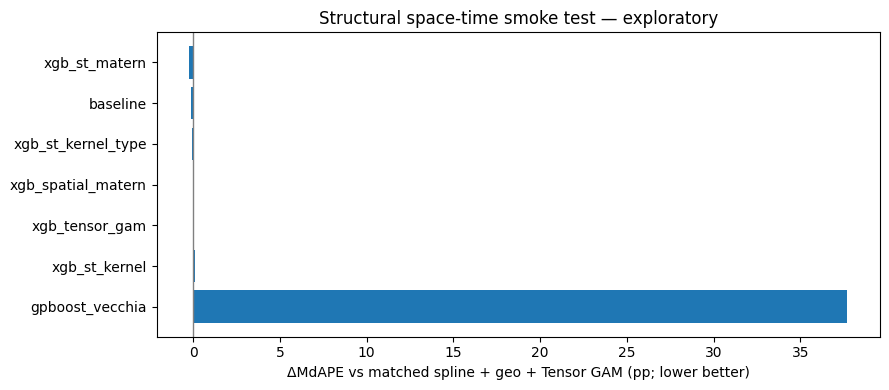

One month cannot reliably eliminate model classes.
Use the three-month pilot below before shortlisting models.


In [4]:
# STEP 2 — inspect which models are even plausible against our incumbent.
# Negative change means an improvement. This cell uses the smoke-run results.
if RUN_STRUCTURAL_SMOKE and "structural_smoke" in globals():
    columns = [
        "variant", "delta_mdape_pp", "delta_mape_pp",
        "delta_vs_tensor_mdape_pp", "delta_vs_tensor_mape_pp",
        "runtime_seconds", "triage",
    ]
    display(structural_smoke[[
        c for c in columns if c in structural_smoke.columns
    ]].round(4))

    if "delta_vs_tensor_mdape_pp" in structural_smoke:
        plot_data = structural_smoke.sort_values("delta_vs_tensor_mdape_pp")
        fig, ax = plt.subplots(figsize=(9, max(4, 0.55 * len(plot_data))))
        ax.barh(plot_data.variant, plot_data.delta_vs_tensor_mdape_pp)
        ax.axvline(0, color="gray", linewidth=1)
        ax.invert_yaxis()
        ax.set_xlabel("ΔMdAPE vs matched spline + geo + Tensor GAM (pp; lower better)")
        ax.set_title("Structural space-time smoke test — exploratory")
        fig.tight_layout()
        plt.show()

    print("One month cannot reliably eliminate model classes.")
    print("Use the three-month pilot below before shortlisting models.")


### Three-month development pilot (opt-in)

After the smoke test succeeds, change `RUN_STRUCTURAL_THREE_MONTH` to `True` and run the cell below. This uses 8,000 past sales, 500 trees and held-out sales from September, October and November 2025. It will take more computation than the smoke test.

Prioritize methods that repeatedly improve **both MdAPE and MAPE**, have acceptable runtime, and beat the **matched Tensor GAM** rather than just the uncorrected XGBoost. The `triage` column is a conservative screening heuristic, not proof that any model can or cannot win after tuning.

Changing training budgets changes the experimental fingerprint: use a different `output_dir` instead of mixing caches. Completed monthly predictions are checkpointed and reused with `resume=True`.


In [5]:
# STEP 3 — more discriminating screen on three earlier monthly holdouts.
RUN_STRUCTURAL_THREE_MONTH = False   # Enable after reviewing smoke output

THREE_MONTH_SETTINGS = dict(
    months=("2025-09", "2025-10", "2025-11"),
    train_start="2022-01-01",
    train_cap=8_000,
    validation_cap=900,
    calibration_cap=450,
    calibration_folds=2,
    trees=500,
    gpboost_rounds=220,
    max_gp_points=350,
    residual_strength=0.5,
    methods=ACTIVE_STRUCTURAL_METHODS,
    seed=42,
    bootstrap_repeats=500,
    output_dir="outputs/spacetime_structural_notebook_three_month",
    resume=True,
)

THREE_MONTH_SETTINGS["methods"] = (
    "xgb_tensor_gam",
    "xgb_spatial_matern",
    "xgb_st_matern",
    "xgb_st_kernel_type",
)

THREE_MONTH_SETTINGS["output_dir"] = (
    "outputs/spacetime_structural_three_month_shortlist"
)

RUN_STRUCTURAL_THREE_MONTH = False  # Already completed; enable to rerun

if RUN_STRUCTURAL_THREE_MONTH:
    structural_pooled, structural_monthly, structural_predictions, structural_failures = (
        run_structural_shotgun(**THREE_MONTH_SETTINGS)
    )
    display(structural_pooled.round(4))
    display(structural_monthly.round(4))
    if not structural_failures.empty:
        display(structural_failures[[
            "month", "variant", "error_type", "message"
        ]])
    print("Full pilot outputs:", THREE_MONTH_SETTINGS["output_dir"])



2025-09: 900 matched off-market held-out homes
  xgb_tensor_gam: 30.6s
  xgb_spatial_matern: 0.0s
  xgb_st_matern: 0.0s
  xgb_st_kernel_type: 0.0s

2025-10: 900 matched off-market held-out homes
  xgb_tensor_gam: 10.9s
  xgb_spatial_matern: 0.0s
  xgb_st_matern: 0.0s
  xgb_st_kernel_type: 0.0s

2025-11: 900 matched off-market held-out homes
  xgb_tensor_gam: 10.9s
  xgb_spatial_matern: 0.0s
  xgb_st_matern: 0.0s
  xgb_st_kernel_type: 0.0s

DEVELOPMENT SHOTGUN (vs matched XGBoost; negative = better):
           variant  homes     mdape      mape  delta_mdape_pp  delta_mape_pp  months_better_mdape  runtime_seconds                    triage
    xgb_tensor_gam   2700 10.798323 13.437110       -0.077779      -0.132077                    2        52.436860      incumbent_tensor_gam
     xgb_st_matern   2700 10.846795 13.540392       -0.029307      -0.028795                    2         0.057524              inconclusive
xgb_st_kernel_type   2700 10.865880 13.497244       -0.010222      -0.0

,variant,homes,mdape,mape,delta_mdape_pp,delta_mape_pp,homes_improved_pct,months_better_mdape,runtime_seconds,mdape_ci_low,mdape_ci_high,mape_ci_low,mape_ci_high,triage,delta_vs_tensor_mdape_pp,delta_vs_tensor_mape_pp
1,xgb_tensor_gam,2700,10.7983,13.4371,-0.0778,-0.1321,51.4444,2,52.4369,-0.2220,0.1473,-0.1797,-0.0903,incumbent_tensor_gam,0.0000,0.0000
3,xgb_st_matern,2700,10.8468,13.5404,-0.0293,-0.0288,51.2593,2,0.0575,-0.2510,0.2095,-0.0898,0.0410,inconclusive,0.0485,0.1033
4,xgb_st_kernel_type,2700,10.8659,13.4972,-0.0102,-0.0719,51.5185,1,0.0419,-0.1822,0.1851,-0.1128,-0.0326,inconclusive,0.0676,0.0601
0,baseline,2700,10.8761,13.5692,0.0000,0.0000,0.0000,0,40.3193,0.0000,0.0000,0.0000,0.0000,reference_xgb_splines_geo,0.0778,0.1321
2,xgb_spatial_matern,2700,10.8921,13.4315,0.0160,-0.1377,50.3333,1,0.0559,-0.2063,0.2644,-0.2090,-0.0674,inconclusive,0.0937,-0.0056


,month,variant,homes,mdape,mape,delta_mdape_pp,delta_mape_pp,delta_vs_tensor_mdape_pp,delta_vs_tensor_mape_pp
0,2025-09,baseline,900,10.3827,13.4105,0.0000,0.0000,-0.2094,0.2058
1,2025-10,baseline,900,11.1108,13.4195,0.0000,0.0000,0.1651,0.1269
2,2025-11,baseline,900,11.1441,13.8776,0.0000,0.0000,0.1445,0.0636
3,2025-09,xgb_tensor_gam,900,10.5921,13.2047,0.2094,-0.2058,0.0000,0.0000
4,2025-10,xgb_tensor_gam,900,10.9457,13.2927,-0.1651,-0.1269,0.0000,0.0000
5,2025-11,xgb_tensor_gam,900,10.9996,13.8140,-0.1445,-0.0636,0.0000,0.0000
6,2025-09,xgb_spatial_matern,900,10.5480,13.3697,0.1653,-0.0408,-0.0441,0.1650
7,2025-10,xgb_spatial_matern,900,11.2917,13.2815,0.1809,-0.1380,0.3460,-0.0111
8,2025-11,xgb_spatial_matern,900,10.8350,13.6433,-0.3091,-0.2343,-0.1646,-0.1707
9,2025-09,xgb_st_matern,900,10.3420,13.4613,-0.0407,0.0509,-0.2501,0.2566


Full pilot outputs: outputs/spacetime_structural_three_month_shortlist


---

## Archived GPBoost failure diagnosis (optional, not part of active shotgun)

The first October 2025 smoke test showed roughly **48.8% MdAPE** for the independent GPBoost model. The component diagnostic established **48.7828% MdAPE for both the jointly trained tree-only and combined model**. The median GP correction was zero and the log-scale decomposition was numerically exact; most of the error is in the fitted boosting component. **GPBoost is therefore removed from active screening**, not declared fundamentally incapable of performing well after tuning.

The structural smoke XGBoost uses the *tuned* model parameters **except** for its 250 trees / 5,000 historical training sales. The three-month XGBoost uses 500 trees / 8,000 historical sales; the established full-history validation used 700 trees and an expanding historical population. Thus, compare models **within each identical validation fold**, never compare the raw 250-home pilot MdAPE to the full-history MdAPE of 7.4857%.

**First diagnostic cell:** inspect the already saved GPBoost predictions and their absolute/signed errors without fitting anything.

**Second diagnostic cell:** optionally refit GPBoost *once* with the same October smoke train/holdout and inspect its **tree-only**, **GP random-effect**, and **combined** log predictions. In Gaussian GPBoost, `response_mean = fixed_effect + random_effect_mean` on the centered log-target scale. The diagnostic checks that identity instead of assuming the prediction scale is correct. We retain the original prediction calculation; this is instrumentation, not a new model.

GPBoost's 180-round LightGBM-style tree with a different learning rate and regularization is **not** hyperparameter-matched to our highly tuned XGBoost, even if it receives the same feature family. Treat the tree-only metrics as an essential sanity check.


In [ ]:
# STEP A: This reads predictions ALREADY produced by the smoke test.
# No new model fitting, no extra GPBoost training time.
# Use the original archived GPBoost smoke output, not the updated
# GPBoost-free active smoke settings.
archived_gpboost_file = Path(
    "outputs/spacetime_structural_notebook_smoke/predictions.csv"
)
if archived_gpboost_file.is_file():
    smoke_audit = pd.read_csv(archived_gpboost_file)
elif ("structural_smoke_predictions" in globals() and
      "gpboost_vecchia" in set(structural_smoke_predictions.variant)):
    smoke_audit = structural_smoke_predictions.copy()
else:
    raise FileNotFoundError(
        "Archived GPBoost smoke predictions are unavailable; "
        "do not rerun GPBoost merely to populate this optional audit."
    )
smoke_audit["ml_num"] = smoke_audit["ml_num"].astype(str)
audit_models = ["baseline", "xgb_tensor_gam", "gpboost_vecchia"]
available = smoke_audit.loc[smoke_audit["variant"].isin(audit_models)].copy()
if "gpboost_vecchia" not in set(available["variant"]):
    print("GPBoost did not produce successful smoke predictions; inspect smoke failures.")
else:
    available["signed_error_pct"] = 100 * (
        available["predicted_price"] - available["sold_price"]
    ) / available["sold_price"]
    available["ape"] = available["signed_error_pct"].abs()
    available["price_ratio"] = (
        available["predicted_price"] / available["sold_price"]
    )
    overview = available.groupby("variant").agg(
        n=("ml_num", "size"),
        mdape=("ape", "median"),
        mape=("ape", "mean"),
        median_signed_pct=("signed_error_pct", "median"),
        median_predicted_to_actual=("price_ratio", "median"),
        predicted_price_median=("predicted_price", "median"),
        actual_price_median=("sold_price", "median"),
    )
    display(overview.round(4))
    print("GPBoost signed percentage-error quantiles:")
    display(available.loc[available.variant == "gpboost_vecchia",
                          "signed_error_pct"].quantile([.01,.10,.25,.50,.75,.90,.99]))
    print("Actual and predicted GPBoost price quantiles:")
    display(available.loc[available.variant == "gpboost_vecchia",
                          ["sold_price", "predicted_price"]]
            .quantile([.01,.10,.50,.90,.99]).round(0))
    print("Interpretation: systematic under/overprediction indicates a scale/intercept")
    print("or mean-model problem; widespread deviations indicate broader model failure.")


In [ ]:
# STEP B: Optional deep diagnosis, requires ONE NEW GPBoost fit on the
# SAME homes and training sample as the October smoke run.
# It can take substantially longer than the other residual corrections.
RUN_GPBOOST_DEEP_DIAGNOSTIC = False  # Set True to inspect the tree and GP parts

if RUN_GPBOOST_DEEP_DIAGNOSTIC:
    import importlib
    from pathlib import Path
    import numpy as np
    import data
    import models.spacetime_gpboost as gpboost_module
    from spacetime_fast import _cap
    gpboost_module = importlib.reload(gpboost_module)

    assert len(SMOKE_SETTINGS["months"]) == 1, (
        "The deep diagnostic uses a single smoke month."
    )
    origin = pd.Period(SMOKE_SETTINGS["months"][0], freq="M")
    sales = data.load("listings")
    sales["date_sold"] = pd.to_datetime(sales["date_sold"])
    train_start = pd.Timestamp(SMOKE_SETTINGS["train_start"])
    train = _cap(
        sales.loc[(sales.date_sold >= train_start) &
                  (sales.date_sold < origin.start_time)],
        SMOKE_SETTINGS["train_cap"], SMOKE_SETTINGS["seed"],
    )
    held = _cap(
        sales.loc[sales.date_sold.dt.to_period("M") == origin],
        SMOKE_SETTINGS["validation_cap"], SMOKE_SETTINGS["seed"] + 11,
    )
    assert len(held) and len(train)
    hidden = data.hide_answers(held, "off_market")

    # This returns separate, UNROUNDED log/price components after a fresh fit.
    details = gpboost_module.gpboost_joint(
        train, hidden, rounds=SMOKE_SETTINGS["gpboost_rounds"],
        seed=SMOKE_SETTINGS["seed"], return_components=True,
    )
    diagnostic = pd.DataFrame({
        "ml_num": held.ml_num.astype(str).to_numpy(),
        "sold_price": held.sold_price.to_numpy(dtype=float),
        "gpboost_combined": details["price_combined"],
        "gpboost_tree_only": details["price_tree_only"],
        "gp_effect_log": details["log_random_effect"],
        "fixed_effect_log": details["log_fixed"],
        "joint_log": details["log_combined"],
    })
    baseline_predictions = structural_smoke_predictions.loc[
        (structural_smoke_predictions.variant == "baseline") &
        (structural_smoke_predictions.month == str(origin)),
        ["ml_num", "predicted_price"],
    ].copy()
    baseline_predictions["ml_num"] = baseline_predictions.ml_num.astype(str)
    if baseline_predictions.ml_num.duplicated().any():
        raise ValueError("Duplicate saved XGBoost validation keys")
    if set(baseline_predictions.ml_num) != set(diagnostic.ml_num):
        raise ValueError("Cached smoke baseline is from a different holdout cohort")
    diagnostic = diagnostic.merge(
        baseline_predictions.rename(columns={
            "predicted_price": "xgboost_splines_geo"
        }), on="ml_num", validate="one_to_one",
    )

    def component_score(label, predicted):
        error = 100 * np.abs(predicted - diagnostic.sold_price) / diagnostic.sold_price
        signed = 100 * (predicted - diagnostic.sold_price) / diagnostic.sold_price
        return {
            "model": label, "mdape": error.median(), "mape": error.mean(),
            "median_signed_pct": signed.median(),
            "median_predicted_price": np.median(predicted),
        }

    results = [
        component_score(col, diagnostic[col])
        for col in ("xgboost_splines_geo", "gpboost_tree_only", "gpboost_combined")
    ]
    display(pd.DataFrame(results).sort_values("mdape").round(4))
    print("Check Gaussian decomposition (response_mean = fixed + random):")
    print("Maximum log-decomposition gap:", details["log_decomposition_gap"])
    print("Max tree-only vs fixed-effect gap:", details["log_tree_vs_fixed_gap"])
    print("Random-effect log quantiles:")
    display(diagnostic.gp_effect_log.quantile([0,.01,.1,.5,.9,.99,1]))
    print("Joint & tree-only log-prediction quantiles:")
    display(diagnostic[["fixed_effect_log", "joint_log"]]
            .quantile([.01,.1,.5,.9,.99]).round(4))
    print("Training log-target range:",
          details["train_log_target_min"], details["train_log_target_max"])
    print("GPBoost model metadata:",
          {k: details[k] for k in (
              "training_rows", "feature_count", "categorical_feature_count",
              "model_rounds", "train_target_offset"
          )})

    output_path = Path(SMOKE_SETTINGS["output_dir"]) / "gpboost_component_diagnostic.csv"
    output_path.parent.mkdir(parents=True, exist_ok=True)
    diagnostic.to_csv(output_path, index=False)
    print("Saved paired diagnostic per home to:", output_path)

    if details["log_decomposition_gap"] > 1e-4:
        print("WARNING: GPBoost response and latent decomposition disagree.")
    elif results[1]["mdape"] < results[2]["mdape"] * .7:
        print("The tree-only component looks substantially better than combined.")
        print("Investigate GP covariance or GP-effect extrapolation.")
    else:
        print("If tree-only error is also severe, investigate tree capacity,")
        print("feature encoding, centering, and GPBoost hyperparameters first.")


---

## Tune Matérn spatial and space-time corrections (XGBoost stays fixed)

We keep **exactly the existing tuned 500-tree pilot XGBoost with spline + geographic context features**, then learn the remaining log-price error with a Matérn-3/2 Gaussian process. This is **not a new XGBoost feature** and **does not retrain XGBoost for every GP trial**.

For a sold-price prediction, the correction is
\[
\widehat P_{\mathrm{corrected}}
=\widehat P_{\mathrm{XGB}}\exp\left(\alpha\,\mathrm{clip}(\widehat r_{\mathrm{GP}},-0.25,0.25)\right).
\]
The correction is calibrated only from *prior-month genuinely out-of-time XGBoost errors*.

We tune **spatial length scale (km)**, **temporal length scale (months, space-time GP only)**, **latent GP variance**, **noise variance**, and **correction strength**. Each trial uses the same original XGBoost validation homes and cached predictions. A lightweight seeded random search avoids requiring Optuna; first trial reproduces the fixed-kernel GP benchmark.

**Stage 1 — selection:** May–July 2025. Three chronological development months, with still-earlier OOT calibration months. The objective is `0.65 × MdAPE + 0.35 × MAPE`; both metrics and month consistency are reported.

**Stage 2 — later development comparison:** September–November 2025, with the kernel settings *frozen from Stage 1*. Compare against both the identical XGBoost and Tensor GAM. These months have been examined before, so this is **not independent final confirmation**. We still need a separate truly untouched period to make final model-selection claims.

The full 700-tree, expanding-history off-market best of about **7.49% MdAPE** is a separate benchmark and must not be compared directly to these reduced-data pilot raw errors. If a Matérn correction wins consistently, rerun it with the full original validation protocol.


In [ ]:
# Matérn kernel-only search on earlier chronological folds.
# XGBoost hyperparameters, feature names, train-cap and tree count are FIXED.
from IPython.display import display
import pandas as pd
from spacetime_matern_tuning import (
    run_matern_tuning, run_matern_confirmation
)

RUN_MATERN_TUNING = True
MATERN_TRIALS_PER_FAMILY = 20   # 1 historical default + 19 candidate kernels

MATERN_SETTINGS = dict(
    tune_months=("2025-05", "2025-06", "2025-07"),
    train_start="2022-01-01",
    train_cap=8_000,
    validation_cap=900,
    calibration_cap=450,
    calibration_folds=2,
    trees=500,
    max_gp_points=350,
    seed=42,
    output_dir="outputs/spacetime_matern_chronological_tuning",
    resume=True,
)

if RUN_MATERN_TUNING:
    matern_trials, matern_best = run_matern_tuning(
        **MATERN_SETTINGS,
        trials_per_family=MATERN_TRIALS_PER_FAMILY,
    )
    print("Best parameters, selected ONLY on early months:")
    display(pd.DataFrame(matern_best["best"]).T.round(5))
    display(matern_trials.sort_values(["kind", "objective"]).groupby(
        "kind", sort=False
    ).head(5).round(5))
    print("Cached results:", MATERN_SETTINGS["output_dir"])


In [ ]:
# Matérn vs Tensor GAM on LATER development months.
# Enable only after kernel selection has finished above.
RUN_MATERN_LATER_COMPARISON = False

if RUN_MATERN_LATER_COMPARISON:
    matern_pooled, matern_monthly, matern_predictions = (
        run_matern_confirmation(
            **MATERN_SETTINGS,
            confirm_months=("2025-09", "2025-10", "2025-11"),
            bootstrap_repeats=500,
        )
    )
    comparison_cols = [
        "variant", "homes", "mdape", "mape",
        "delta_mdape_pp", "delta_mape_pp",
        "delta_vs_tensor_mdape_pp", "delta_vs_tensor_mape_pp",
        "months_better_mdape", "mdape_ci_low", "mdape_ci_high",
        "mape_ci_low", "mape_ci_high",
    ]
    display(matern_pooled[comparison_cols].round(4))
    display(matern_monthly.round(4))

    import matplotlib.pyplot as plt
    chart = matern_pooled.sort_values("delta_vs_tensor_mdape_pp")
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(chart["variant"], chart["delta_vs_tensor_mdape_pp"])
    ax.axvline(0, color="gray", linewidth=1)
    ax.invert_yaxis()
    ax.set_xlabel("ΔMdAPE against matched Tensor GAM (pp; lower is better)")
    ax.set_title("Frozen tuned Matérn versus Tensor GAM — development months")
    fig.tight_layout()
    plt.show()
    print("Paired predictions:", MATERN_SETTINGS["output_dir"])
